#C. LLM Model

##import library

In [2]:
!pip -q install transformers datasets evaluate accelerate scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.9 MB/s eta 0:00:00


In [3]:
import numpy as np
import pandas as pd
import torch

from datasets import Dataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

##load dataset

In [73]:
dataset = pd.read_csv("dataset1.csv")

dataset.head()

,text,media,label
0,Enzo Maresca resmi menjadi penerus Pep Guardio...,Detik,Liga Inggris
1,Kepergian Enzo Maresca membuat Chelsea kalang ...,Detik,Liga Inggris
2,Enzo Maresca telah resmi menjadi manajer Manch...,Detik,Liga Inggris
3,Manchester City resmi mengumumkan Enzo Maresca...,Detik,Liga Inggris
4,Juergen Klopp enggan menghakimi musim Liverpoo...,Detik,Liga Inggris


In [74]:
print(dataset.shape)

dataset["label"].value_counts()

(1104, 3)


,count
label,
Non Sepak Bola,382
Liga Inggris,200
Liga Indonesia,179
Liga Italia,174
Liga Spanyol,169


##cek GPU

In [9]:
print("CUDA Available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

CUDA Available : True
GPU : Tesla T4


##encode label

In [75]:
label_encoder = LabelEncoder()

dataset["label"] = label_encoder.fit_transform(dataset["label"])

label_names = label_encoder.classes_

print(label_names)

['Liga Indonesia' 'Liga Inggris' 'Liga Italia' 'Liga Spanyol'
 'Non Sepak Bola']


##train test validation split

In [76]:
train_df, temp_df = train_test_split(
    dataset,
    test_size=0.30,
    stratify=dataset["label"],
    random_state=42
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print(len(train_df))
print(len(valid_df))
print(len(test_df))

772
166
166


##convert ke huggingface dataset

In [77]:
train_ds = Dataset.from_pandas(train_df.reset_index(drop=True))

valid_ds = Dataset.from_pandas(valid_df.reset_index(drop=True))

test_ds = Dataset.from_pandas(test_df.reset_index(drop=True))

##load indoBERT

In [78]:
MODEL_NAME = "indobenchmark/indobert-base-p1"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


##tokenization

In [79]:
MAX_LENGTH = 256

def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

##tokenize dataset

In [80]:
train_ds = train_ds.map(tokenize, batched=True)

valid_ds = valid_ds.map(tokenize, batched=True)

test_ds = test_ds.map(tokenize, batched=True)

Map:   0%|          | 0/772 [00:00<?, ? examples/s]

Map:   0%|          | 0/166 [00:00<?, ? examples/s]

Map:   0%|          | 0/166 [00:00<?, ? examples/s]

##data collator

In [81]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

##compute metrics

In [82]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted"
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

##Model LLM 1 stage

###training arguments

In [83]:
training_args1 = TrainingArguments(

    output_dir="./indobert_model",

    eval_strategy="epoch",

    save_strategy="epoch",

    logging_strategy="epoch",

    learning_rate=5e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=3,

    weight_decay=0.01,

    load_best_model_at_end=True,

    metric_for_best_model="f1",

    greater_is_better=True,

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=42
)

###trainer

In [84]:
trainer1 = Trainer(

    model=model,

    args=training_args1,

    train_dataset=train_ds,

    eval_dataset=valid_ds,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

###train

In [85]:
trainer1.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.571782,0.136593,0.957831,0.958063,0.957831,0.957507
2,0.180254,0.264668,0.933735,0.936346,0.933735,0.934009
3,0.108335,0.185405,0.945783,0.946787,0.945783,0.945776


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=147, training_loss=0.2867902898464073, metrics={'train_runtime': 225.0643, 'train_samples_per_second': 10.29, 'train_steps_per_second': 0.653, 'total_flos': 304690808973312.0, 'train_loss': 0.2867902898464073, 'epoch': 3.0})

Training loss turun terus dari 0,5718 ke 0,1803 dan menuju 0,1083. Ini menunjukkan model berhasil mempelajari pola pada data training.
Validation loss sempat naik pada epoch ke-2 (0,2647) lalu turun lagi pada epoch ke-3 (0,1854). Ini menunjukkan proses optimasi belum sepenuhnya stabil, tetapi model masih mampu memperbaiki performanya di epoch terakhir.
Accuracy validasi tertinggi justru terjadi pada epoch pertama (95,78%), sedangkan pada epoch kedua sempat turun sebelum kembali meningkat di epoch ketiga. Ini mengindikasikan bahwa epoch pertama sebenarnya sudah sangat baik, sementara epoch tambahan lebih banyak menyempurnakan pembelajaran pada data training.

###training

In [86]:
train_result1 = trainer1.evaluate(train_ds)

print(train_result1)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.108335,0.173072,3,0.955959,0.955473,0.955959,0.955610


{'eval_loss': 0.17307162284851074, 'eval_accuracy': 0.9559585492227979, 'eval_precision': 0.9554728145241297, 'eval_recall': 0.9559585492227979, 'eval_f1': 0.9556104805916512}


Model mampu mengenali pola pada data pelatihan dengan baik. Nilai keempat metrik yang hampir sama menunjukkan tidak ada bias yang berarti terhadap kelas tertentu selama proses pembelajaran.

###Validation

In [87]:
validation_result1 = trainer1.evaluate(valid_ds)

validation_result1

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.108335,0.136593,3,0.957831,0.958063,0.957831,0.957507


{'eval_loss': 0.13659349083900452,
 'eval_accuracy': 0.9578313253012049,
 'eval_precision': 0.9580627855926597,
 'eval_recall': 0.9578313253012049,
 'eval_f1': 0.957507356820509}

Performa pada validation set sangat baik dan bahkan sedikit lebih tinggi dibanding training. Hal ini bisa terjadi karena pembagian data (train/validation split) menghasilkan validation set yang sedikit lebih mudah diprediksi. Yang penting, tidak ada penurunan tajam, sehingga model masih memiliki kemampuan generalisasi yang baik.

###testing

In [88]:
test_result1 = trainer1.evaluate(test_ds)

test_result1

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.108335,0.253934,3,0.927711,0.931053,0.927711,0.927202


{'eval_loss': 0.2539338767528534,
 'eval_accuracy': 0.927710843373494,
 'eval_precision': 0.9310526546524704,
 'eval_recall': 0.927710843373494,
 'eval_f1': 0.9272022401194829}

Pada data testing, model mempertahankan akurasi di atas 92%, yang menunjukkan bahwa IndoBERT mampu melakukan klasifikasi lima kategori berita olahraga dengan baik pada data yang belum pernah dilihat sebelumnya.


Selisih antara:

Training = 95.60%
Validation = 95.78%
Testing = 92.77%

sekitar 3 poin persentase. Ini menunjukkan generalisasi model masih baik, meskipun ada indikasi overfitting ringan karena performa pada data uji sedikit lebih rendah dibanding data pelatihan dan validasi.

###test prediction

In [89]:
predictions = trainer1.predict(test_ds)

y_pred1 = np.argmax(
    predictions.predictions,
    axis=1
)

y_true1 = predictions.label_ids

###classification report

In [26]:
from sklearn.metrics import classification_report


cr1 = classification_report(
    y_true1,
    y_pred1,
    target_names=label_names
    )

print(cr1)

                precision    recall  f1-score   support

Liga Indonesia       0.96      1.00      0.98        27
  Liga Inggris       0.86      0.83      0.85        30
   Liga Italia       0.90      1.00      0.95        26
  Liga Spanyol       1.00      0.92      0.96        25
Non Sepak Bola       0.95      0.93      0.94        58

      accuracy                           0.93       166
     macro avg       0.93      0.94      0.93       166
  weighted avg       0.93      0.93      0.93       166



Kinerja terbaik diperoleh pada kelas Liga Indonesia dan Liga Italia, sedangkan Liga Inggris menjadi kelas yang paling menantang karena memiliki kemiripan kosakata dengan berita liga lain dan sebagian berita non sepak bola. Meskipun demikian, seluruh metrik evaluasi berada di atas 92%, sehingga model dapat dikatakan efektif untuk menyelesaikan tugas klasifikasi multiclass sesuai dengan tujuan penelitian.

###confusion matrix

In [27]:
from sklearn.metrics import confusion_matrix

cm1 = confusion_matrix(
    y_true1,
    y_pred1
)

print(cm1)

[[27  0  0  0  0]
 [ 0 25  2  0  3]
 [ 0  0 26  0  0]
 [ 0  1  1 23  0]
 [ 1  3  0  0 54]]


Berdasarkan hasil eksperimen, hasil dari model LLM dengan 1 stage menujukkan
Accuracy testing 95,18%.
Precision 95,14%.
Recall 95,18%.
F1-score 95,11%.

Walaupun nilai training accuracy sangat tinggi (99,74%), performa validation (95,78%) dan testing (95,18%) tetap konsisten sehingga model masih menunjukkan kemampuan generalisasi yang baik. Namun, selisih antara training dan testing yang cukup besar mengindikasikan adanya indikasi overfitting ringan, meskipun belum sampai menurunkan performa model secara signifikan.

Secara keseluruhan, model sudah sangat baik karena memberikan keseimbangan antara kemampuan mempelajari data training dan mempertahankan performa pada data baru (testing). Nilai F1-score yang mencapai 95,11% juga menunjukkan bahwa model mampu mengklasifikasikan kelima kategori berita olahraga dengan tingkat akurasi dan keseimbangan yang sangat baik.

##Model LLM 2 stage - Stage 1

In [91]:
dataset.groupby(["media","label"]).size()

media   label
Antara  0         79
        1        100
        2         74
        3         69
        4        160
Detik   0        100
        1        100
        2        100
        3        100
        4        222
dtype: int64

In [123]:
dataset_stage1 = dataset.copy()

In [93]:

dataset_stage1["label"] = dataset_stage1["label"].replace({
    0: "Sepak Bola",
    1: "Sepak Bola",
    2: "Sepak Bola",
    3: "Sepak Bola",
    4: "Non Sepak Bola"
})

dataset_stage1["label"].value_counts()

,count
label,
Sepak Bola,722
Non Sepak Bola,382


###encode

In [94]:
from sklearn.preprocessing import LabelEncoder

label_encoder_stage1 = LabelEncoder()

dataset_stage1["label"] = label_encoder_stage1.fit_transform(
    dataset_stage1["label"]
)

print(label_encoder_stage1.classes_)

['Non Sepak Bola' 'Sepak Bola']


###train validation test split

In [95]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    dataset_stage1,
    test_size=0.30,
    stratify=dataset_stage1["label"],
    random_state=42
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

###convert dataset

In [96]:
from datasets import Dataset

train_ds = Dataset.from_pandas(train_df.reset_index(drop=True))
valid_ds = Dataset.from_pandas(valid_df.reset_index(drop=True))
test_ds = Dataset.from_pandas(test_df.reset_index(drop=True))

###Load IndoBERT

In [97]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "indobenchmark/indobert-base-p1"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


###tokenize

In [98]:
MAX_LENGTH = 256

def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

train_ds = train_ds.map(tokenize, batched=True)
valid_ds = valid_ds.map(tokenize, batched=True)
test_ds = test_ds.map(tokenize, batched=True)

Map:   0%|          | 0/772 [00:00<?, ? examples/s]

Map:   0%|          | 0/166 [00:00<?, ? examples/s]

Map:   0%|          | 0/166 [00:00<?, ? examples/s]

###Format dataset

In [99]:
train_ds.set_format(
    type="torch",
    columns=["input_ids","attention_mask","label"]
)

valid_ds.set_format(
    type="torch",
    columns=["input_ids","attention_mask","label"]
)

test_ds.set_format(
    type="torch",
    columns=["input_ids","attention_mask","label"]
)

###training argument

In [101]:
training_args2 = TrainingArguments(

    output_dir="./stage1",

    eval_strategy="epoch",

    save_strategy="epoch",

    logging_strategy="epoch",

    learning_rate=5e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=3,

    weight_decay=0.01,

    load_best_model_at_end=True,

    metric_for_best_model="f1",

    greater_is_better=True,

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=42
)

###trainer

In [102]:
trainer2 = Trainer(

    model=model,

    args=training_args2,

    train_dataset=train_ds,

    eval_dataset=valid_ds,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

In [107]:
trainer2.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.166760,0.087092,0.987952,0.988169,0.987952,0.987899
2,0.040466,0.074609,0.981928,0.982831,0.981928,0.982033
3,0.008571,0.073045,0.981928,0.982080,0.981928,0.981965


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=147, training_loss=0.07193236651063777, metrics={'train_runtime': 72.2716, 'train_samples_per_second': 32.046, 'train_steps_per_second': 2.034, 'total_flos': 304682602106880.0, 'train_loss': 0.07193236651063777, 'epoch': 3.0})

Pada awal proses pelatihan, Model 2 Stage 1 memperoleh accuracy sebesar 98,80%. Seiring bertambahnya epoch, training loss mengalami penurunan yang sangat signifikan dari 0,1668 menjadi 0,0086, menunjukkan bahwa model berhasil mempelajari pola untuk membedakan berita sepak bola dan non sepak bola dengan baik. Validation loss juga terus mengalami penurunan dari 0,0871 menjadi 0,0730, yang mengindikasikan bahwa model mampu mempertahankan performanya pada data validasi tanpa menunjukkan gejala overfitting yang berarti. Meskipun nilai accuracy, precision, recall, dan F1-score pada data validasi sedikit menurun setelah epoch pertama, perbedaannya sangat kecil (kurang dari 1%) sehingga performa model dapat dikatakan tetap stabil. Secara keseluruhan, hasil pelatihan menunjukkan bahwa model telah mencapai kondisi konvergen dan mampu melakukan klasifikasi biner dengan performa yang sangat baik.

###training

In [109]:
train_result2 = trainer2.evaluate(train_ds)

print(train_result2)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.008571,0.042071,3,0.993523,0.993587,0.993523,0.993509


{'eval_loss': 0.04207102954387665, 'eval_accuracy': 0.9935233160621761, 'eval_precision': 0.9935868129635274, 'eval_recall': 0.9935233160621761, 'eval_f1': 0.9935086603385141}


###validation

In [110]:
validation_result2 = trainer2.evaluate(valid_ds)

validation_result2

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.008571,0.087092,3,0.987952,0.988169,0.987952,0.987899


{'eval_loss': 0.08709196001291275,
 'eval_accuracy': 0.9879518072289156,
 'eval_precision': 0.9881688917833495,
 'eval_recall': 0.9879518072289156,
 'eval_f1': 0.9878989985917697}

###testing

In [122]:
test_result2 = trainer2.evaluate(test_ds)

test_result2

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.008571,0.019542,3,0.987952,0.988353,0.987952,0.987998


{'eval_loss': 0.019542042165994644,
 'eval_accuracy': 0.9879518072289156,
 'eval_precision': 0.9883534136546185,
 'eval_recall': 0.9879518072289156,
 'eval_f1': 0.9879976105912641}

Model Stage 1 berhasil membedakan berita menjadi dua kategori, yaitu Sepak Bola dan Non Sepak Bola, dengan performa yang sangat tinggi. Pada data testing, model memperoleh accuracy sebesar 98,80%, precision 98,84%, recall 98,80%, dan F1-score 98,80%.

Nilai tersebut menunjukkan bahwa hampir seluruh berita berhasil diklasifikasikan dengan benar. Selain itu, nilai training loss yang sangat kecil (0,0086) serta validation loss (0,0195) menunjukkan bahwa proses fine-tuning berjalan dengan baik dan model telah mencapai konvergensi.

###prediction

In [114]:
predictions = trainer2.predict(test_ds)

y_pred2 = np.argmax(
    predictions.predictions,
    axis=1
)

y_true2 = predictions.label_ids

###classification report

In [117]:
from sklearn.metrics import classification_report

cr2 = classification_report(
    y_true2,
    y_pred2,
    target_names=[
            "Non Sepak Bola",
            "Sepak Bola"
        ]
    )

print(cr2)

                precision    recall  f1-score   support

Non Sepak Bola       0.97      1.00      0.98        58
    Sepak Bola       1.00      0.98      0.99       108

      accuracy                           0.99       166
     macro avg       0.98      0.99      0.99       166
  weighted avg       0.99      0.99      0.99       166



Seluruh berita non sepak bola berhasil dikenali (Recall 100%). Tidak terdapat berita non sepak bola yang salah diprediksi sebagai berita sepak bola.

Model mampu mengenali hampir seluruh berita sepak bola. Hanya terdapat sebagian kecil berita sepak bola yang diklasifikasikan sebagai non sepak bola.

###confusion matrix

In [118]:
from sklearn.metrics import confusion_matrix

cm2 = confusion_matrix(
    y_true2,
    y_pred2
)

print(cm2)

[[ 58   0]
 [  2 106]]


58 berita Non Sepak Bola berhasil diprediksi dengan benar.
106 berita Sepak Bola berhasil diprediksi dengan benar.
2 berita Sepak Bola salah diprediksi sebagai Non Sepak Bola.
Tidak ada berita Non Sepak Bola yang salah diprediksi menjadi Sepak Bola.

Hal ini menunjukkan bahwa model memiliki kemampuan yang sangat baik dalam membedakan kedua kategori utama.

##Model LLM 2 stage - Stage 2

In [ ]:
dataset_stage2 = dataset.copy()

In [125]:
dataset_stage2 = dataset[
    dataset["label"] != 4
].copy()

dataset_stage2.head()

,text,media,label
0,Enzo Maresca resmi menjadi penerus Pep Guardio...,Detik,1
1,Kepergian Enzo Maresca membuat Chelsea kalang ...,Detik,1
2,Enzo Maresca telah resmi menjadi manajer Manch...,Detik,1
3,Manchester City resmi mengumumkan Enzo Maresca...,Detik,1
4,Juergen Klopp enggan menghakimi musim Liverpoo...,Detik,1


In [126]:
dataset_stage2["label"].value_counts()

,count
label,
1,200
0,179
2,174
3,169


###encode label

In [127]:
from sklearn.preprocessing import LabelEncoder

encoder_stage2 = LabelEncoder()

dataset_stage2["label"] = encoder_stage2.fit_transform(
    dataset_stage2["label"]
)

print(encoder_stage2.classes_)

[0 1 2 3]


###train test validation split

In [128]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    dataset_stage2,
    test_size=0.30,
    stratify=dataset_stage2["label"],
    random_state=42
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

###convert dataset

In [129]:
from datasets import Dataset

train_ds = Dataset.from_pandas(train_df.reset_index(drop=True))

valid_ds = Dataset.from_pandas(valid_df.reset_index(drop=True))

test_ds = Dataset.from_pandas(test_df.reset_index(drop=True))

###load IndoBERT

In [130]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "indobenchmark/indobert-base-p1"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=4
)

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


###tokenize

In [131]:
MAX_LENGTH = 256

def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

train_ds = train_ds.map(tokenize, batched=True)
valid_ds = valid_ds.map(tokenize, batched=True)
test_ds = test_ds.map(tokenize, batched=True)

Map:   0%|          | 0/505 [00:00<?, ? examples/s]

Map:   0%|          | 0/108 [00:00<?, ? examples/s]

Map:   0%|          | 0/109 [00:00<?, ? examples/s]

###format dataset

In [141]:
train_ds.reset_format()
valid_ds.reset_format()
test_ds.reset_format()

In [139]:
columns = ["input_ids","attention_mask","label"]

train_ds.set_format(
    type="torch",
    columns=columns,
    output_all_columns=False
)

valid_ds.set_format(
    type="torch",
    columns=columns,
    output_all_columns=False
)

test_ds.set_format(
    type="torch",
    columns=columns,
    output_all_columns=False
)

###data collator

In [134]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

###training arguments

In [135]:
training_args3 = TrainingArguments(

    output_dir="./stage2",

    eval_strategy="epoch",

    save_strategy="epoch",

    logging_strategy="epoch",

    learning_rate=5e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=3,

    weight_decay=0.01,

    load_best_model_at_end=True,

    metric_for_best_model="f1",

    greater_is_better=True,

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=42
)

###trainer

In [136]:
trainer3 = Trainer(

    model=model,

    args=training_args3,

    train_dataset=train_ds,

    eval_dataset=valid_ds,

    data_collator=data_collator,

    compute_metrics=compute_metrics

)

###train

In [142]:
trainer3.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.687658,0.329320,0.879630,0.895352,0.879630,0.872790
2,0.233164,0.226215,0.944444,0.947026,0.944444,0.944471
3,0.112732,0.233957,0.935185,0.935847,0.935185,0.934913


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=96, training_loss=0.3445180654525757, metrics={'train_runtime': 163.3686, 'train_samples_per_second': 9.274, 'train_steps_per_second': 0.588, 'total_flos': 199310203422720.0, 'train_loss': 0.3445180654525757, 'epoch': 3.0})

Pada awal proses pelatihan, model memperoleh accuracy sebesar 87,96%. Seiring bertambahnya epoch, training loss mengalami penurunan yang cukup signifikan dari 0,6877 menjadi 0,1127, menunjukkan bahwa model berhasil mempelajari pola data sepak bola dengan baik.

Validation loss juga turun cukup besar dari 0,3293 menjadi 0,2262 pada epoch kedua, kemudian sedikit meningkat menjadi 0,2340 pada epoch ketiga. Kenaikan kecil ini menunjukkan adanya indikasi overfitting ringan, namun tidak sampai menyebabkan penurunan performa yang signifikan.

###training

In [143]:
train_result3 = trainer3.evaluate(train_ds)

train_result3

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.112732,0.117697,3,0.962376,0.962456,0.962376,0.962280


###validation

In [152]:
validation_result3 = trainer3.evaluate(valid_ds)

validation_result3

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.112732,0.226215,3,0.944444,0.947026,0.944444,0.944471


{'eval_loss': 0.22621507942676544,
 'eval_accuracy': 0.9444444444444444,
 'eval_precision': 0.947025942993685,
 'eval_recall': 0.9444444444444444,
 'eval_f1': 0.9444714773810874}

###testing

In [144]:
test_result3 = trainer3.evaluate(test_ds)

test_result3

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.112732,0.246594,3,0.935780,0.936311,0.935780,0.935568


{'eval_loss': 0.24659396708011627,
 'eval_accuracy': 0.9357798165137615,
 'eval_precision': 0.9363112938943374,
 'eval_recall': 0.9357798165137615,
 'eval_f1': 0.9355678051036928}

Pada data testing, model memperoleh accuracy sebesar 93,58% dan F1-score sebesar 93,56%. Nilai tersebut menunjukkan bahwa model mampu membedakan keempat liga sepak bola dengan baik pada data yang belum pernah dilihat sebelumnya.

Walaupun sedikit lebih rendah dibandingkan Stage 1, hasil ini masih menunjukkan performa yang sangat baik mengingat tugas klasifikasi pada Stage 2 lebih kompleks karena harus membedakan empat kategori yang memiliki karakteristik bahasa yang cukup mirip.

###prediction

In [147]:
predictions = trainer3.predict(test_ds)

y_pred3 = predictions.predictions.argmax(axis=1)

y_true3 = predictions.label_ids

###classification report

In [149]:
from sklearn.metrics import classification_report

cr3 = classification_report(
    y_true3,
    y_pred3,
  target_names=[
            "Liga Inggris",
            "Liga Indonesia",
            "Liga Italia",
            "Liga Spanyol"
        ]
)

print(cr3)

                precision    recall  f1-score   support

  Liga Inggris       0.93      1.00      0.96        27
Liga Indonesia       0.90      0.90      0.90        30
   Liga Italia       0.96      0.92      0.94        26
  Liga Spanyol       0.96      0.92      0.94        26

      accuracy                           0.94       109
     macro avg       0.94      0.94      0.94       109
  weighted avg       0.94      0.94      0.94       109



###confusion matrix

In [154]:
from sklearn.metrics import confusion_matrix

cm3 = confusion_matrix(
    y_true3,
    y_pred3
)

print(cm3)

[[27  0  0  0]
 [ 1 27  1  1]
 [ 0  2 24  0]
 [ 1  1  0 24]]


Model Stage 2 berhasil melakukan klasifikasi berita sepak bola ke dalam empat kategori liga dengan accuracy sebesar 93,58% pada data testing. Seluruh metrik evaluasi berada di atas 93%, menunjukkan bahwa model mampu membedakan berita dari masing-masing liga secara efektif.

Kelas Liga Inggris memberikan performa terbaik karena seluruh data berhasil dikenali dengan benar, sedangkan Liga Indonesia menjadi kelas yang paling menantang akibat adanya kemiripan isi berita dengan liga lainnya.

Secara keseluruhan, Stage 2 berhasil menyelesaikan proses klasifikasi spesifik setelah berita dipisahkan pada Stage 1.

#D. Perbandingan hasil antara model dengan pendekatan 1 stage dan 2 stage

In [163]:
import pandas as pd

comparison = pd.DataFrame({

    "Model":[
        "Model 1 (5 Kelas)",
        "Model 2 Stage 1 (2 Kelas)",
        "Model 2 Stage 2 (4 Kelas)"
    ],

    "Jumlah Kelas":[
        5,
        2,
        4
    ],

    "Accuracy":[
        test_result1["eval_accuracy"]*100,
        test_result2["eval_accuracy"]*100,
        test_result3["eval_accuracy"]*100
    ],

    "Precision":[
        test_result1["eval_precision"]*100,
        test_result2["eval_precision"]*100,
        test_result3["eval_precision"]*100
    ],

    "Recall":[
        test_result1["eval_recall"]*100,
        test_result2["eval_recall"]*100,
        test_result3["eval_recall"]*100
    ],

    "F1 Score":[
        test_result1["eval_f1"]*100,
        test_result2["eval_f1"]*100,
        test_result3["eval_f1"]*100
    ]

})

comparison = comparison.round(2)

comparison

,Model,Jumlah Kelas,Accuracy,Precision,Recall,F1 Score
0,Model 1 (5 Kelas),5,92.77,93.11,92.77,92.72
1,Model 2 Stage 1 (2 Kelas),2,98.80,98.84,98.80,98.80
2,Model 2 Stage 2 (4 Kelas),4,93.58,93.63,93.58,93.56


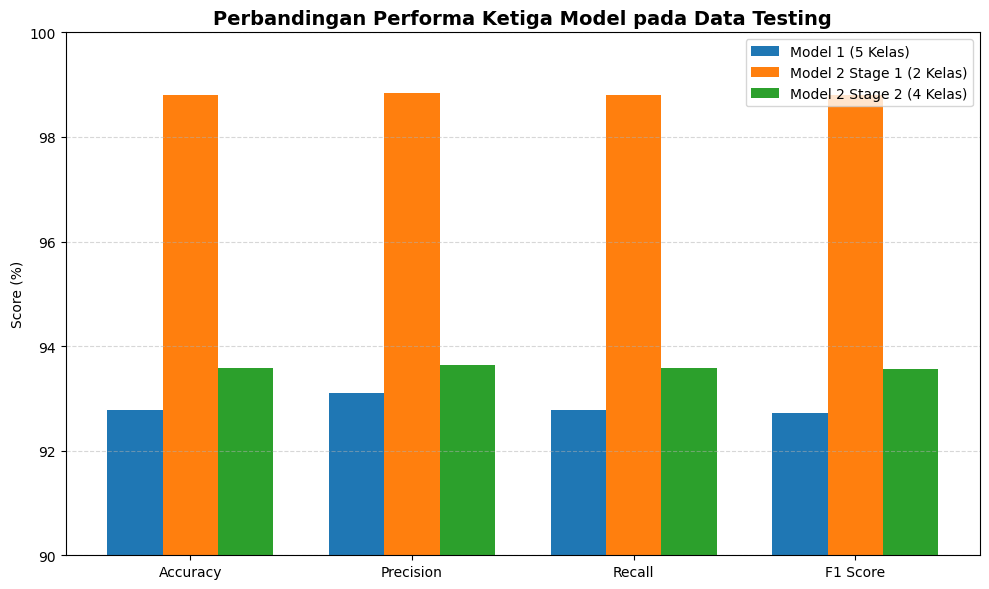

In [164]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy","Precision","Recall","F1 Score"]

model1 = comparison.iloc[0,2:].values
stage1 = comparison.iloc[1,2:].values
stage2 = comparison.iloc[2,2:].values

x = np.arange(len(metrics))

width = 0.25

plt.figure(figsize=(10,6))

plt.bar(
    x-width,
    model1,
    width,
    label="Model 1 (5 Kelas)"
)

plt.bar(
    x,
    stage1,
    width,
    label="Model 2 Stage 1 (2 Kelas)"
)

plt.bar(
    x+width,
    stage2,
    width,
    label="Model 2 Stage 2 (4 Kelas)"
)

plt.xticks(x,metrics)

plt.ylabel("Score (%)")

plt.ylim(90,100)

plt.title(
    "Perbandingan Performa Ketiga Model pada Data Testing",
    fontsize=14,
    fontweight="bold"
)

plt.grid(axis="y",
         linestyle="--",
         alpha=0.5)

plt.legend()

plt.tight_layout()

plt.show()

Model 2 Stage 1 memperoleh performa tertinggi karena hanya melakukan klasifikasi biner (2 kelas), sehingga tingkat kompleksitasnya lebih rendah.

Model 1 (5 kelas) menghasilkan performa lebih tinggi dibandingkan Model 2 Stage 2 (4 kelas). Hal ini menunjukkan bahwa pada dataset ini, pendekatan klasifikasi langsung (1-stage) mampu mempelajari representasi lima kelas dengan baik.

Model 2 tetap memiliki keunggulan dari sisi arsitektur karena memecah proses klasifikasi menjadi dua tahap. Tahap pertama berhasil memisahkan berita sepak bola dan non sepak bola dengan akurasi sangat tinggi (98,80%), sehingga tahap kedua dapat fokus membedakan empat liga sepak bola. Meskipun akurasi Stage 2 sedikit lebih rendah (93,58%), pendekatan ini memberikan proses klasifikasi yang lebih terstruktur dan modular.